# SDM on Imagenette: does it do better on larger images?

This notebook applies the **Similarity-Distance-Magnitude (SDM)** estimator to the ResNet-18 trained from scratch on Imagenette in [notebook 08](08_imagenette_resnet18.ipynb), and compares it with the softmax and temperature-scaling baselines on the same validation images, exactly as [notebook 05](05_sdm_resnet18_cal100.ipynb) and [notebook 07](07_sdm_resnet18_cal100_selected_classes.ipynb) did on CIFAR-100.

On CIFAR-100, SDM formed no region on the 100 classes, and where it did form regions (56 well-handled classes), a softmax threshold with the same coverage was at least as accurate. Imagenette changes three things at once:

- **larger images**: 128 × 128 pixels seen by the network instead of 32 × 32,
- **fewer, more distinct classes**: 10 instead of 100,
- **more calibration images per class**: 200 instead of 100.

So a result here cannot be credited to resolution alone. Section 8 separates them: it puts this run next to the **same Imagenette task at 32 × 32** (notebook 08 with `RESOLUTION = 32`) and next to CIFAR-100.

**Before running:** run notebook 08 first (checkpoint and decoded images). The SDM fit takes a minute or two the first time and is cached in `outputs/`.

## 1. Settings and tools

In [1]:
from pathlib import Path
import hashlib
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import reexpress_sdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from reexpress_sdm import SDMModel, TorchTrainer, TrainingConfig, load_artifact, write_artifact
from sklearn.metrics import roc_auc_score

SDM_EPOCHS = 20        # the package default
SDM_SEED = 0
TARGET_ALPHA = 0.95    # the reliability level we want, as in notebook 08
MODEL_NAME = "imagenette_resnet18"  # saved by notebook 08; "imagenette32px_resnet18" for its RESOLUTION = 32 run
CIFAR_MODEL_NAME = "cifar100_resnet18_cal100"  # notebooks 04-05, for the comparison in section 8
SAVE_SDM_MODELS = True    # cache fitted SDM models in outputs/ and reload them instead of refitting
REBUILD_EMBEDDINGS = False  # True recomputes the embeddings even when a matching cache exists
DATA_DIR = Path("../data")
OUTPUT_DIR = Path("../outputs")

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"PyTorch {torch.__version__}, reexpress-sdm {reexpress_sdm.__version__}, device: {device}")

PyTorch 2.5.1, reexpress-sdm 0.4.9, device: mps


## 2. Load the data and the trained ResNet-18

The decoded images come from the cache notebook 08 wrote in `data/`. The network class must match notebook 08 exactly so the saved weights fit, and the checkpoint stores the split indices, so we use exactly the same training, calibration and validation images.

In [2]:
checkpoint_path = OUTPUT_DIR / f"{MODEL_NAME}.pt"
assert checkpoint_path.exists(), f"{checkpoint_path} not found: run notebook 08 first"
checkpoint_sha256 = hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()  # identifies this exact ResNet for the caches
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
settings = checkpoint["settings"]
class_names = checkpoint["class_names"]

cache_path = DATA_DIR / f"imagenette2-160_{settings['store_size']}px.npz"
assert cache_path.exists(), f"{cache_path} not found: run notebook 08 first"
with np.load(cache_path) as cache:
    all_images, all_labels = cache["train_images"], cache["train_labels"]
print(f"{len(all_images):,} training-folder images, {len(class_names)} classes")

9,469 training-folder images, 10 classes


In [3]:
# Same architecture as notebook 08.
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class ImageNetResNet(nn.Module):
    def __init__(self, num_classes=10, widths=(64, 128, 256, 512), stem="imagenet"):
        super().__init__()
        if stem == "imagenet":
            self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 7, stride=2, padding=3, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(),
                                      nn.MaxPool2d(3, stride=2, padding=1))
        else:
            self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())
        stages, in_channels = [], widths[0]
        for i, width in enumerate(widths):
            stride = 1 if i == 0 else 2
            stages.append(nn.Sequential(ResidualBlock(in_channels, width, stride), ResidualBlock(width, width)))
            in_channels = width
        self.stages = nn.Sequential(*stages)
        self.classifier = nn.Linear(widths[-1], num_classes)

    def embed(self, x):
        return F.adaptive_avg_pool2d(self.stages(self.stem(x)), 1).flatten(1)

    def forward(self, x):
        return self.classifier(self.embed(x))


model = ImageNetResNet(num_classes=len(class_names), stem=settings.get("stem", "imagenet")).to(device)
model.load_state_dict(checkpoint["model_state"])
model.eval()
channel_mean = checkpoint["channel_mean"].to(device)
channel_std = checkpoint["channel_std"].to(device)
splits = checkpoint["split_indices"]          # train / validation / calibration indices into the training folder
TEMPERATURE = checkpoint["temperature"]       # fitted in notebook 08 on the calibration split
print({name: len(index) for name, index in splits.items()}, f"temperature {TEMPERATURE:.2f}")

{'train': 6969, 'validation': 500, 'calibration': 2000} temperature 2.17


## 3. Compute embeddings

As in notebook 05: the **512-number embedding** and the logits of every image, computed on the central 128 × 128 window with no augmentation. The result is cached in `outputs/imagenette_resnet18_embeddings.npz` together with the checkpoint's SHA-256, and reused only if the fingerprint and split indices match.

In [4]:
@torch.no_grad()
def embed_images(images, batch_size=250):
    size, embeddings, logits = settings["crop_size"], [], []
    offset = (images.shape[-1] - size) // 2
    for start in range(0, len(images), batch_size):
        batch = torch.from_numpy(images[start : start + batch_size, :, offset : offset + size, offset : offset + size]).to(device)
        features = model.embed((batch.float() / 255 - channel_mean) / channel_std)
        embeddings.append(features.cpu())
        logits.append(model.classifier(features).cpu())
    return torch.cat(embeddings).numpy(), torch.cat(logits)


embeddings_path = OUTPUT_DIR / f"{MODEL_NAME}_embeddings.npz"


def load_cached_embeddings():
    # The cache is valid only for this exact checkpoint and these exact splits.
    if REBUILD_EMBEDDINGS or not embeddings_path.exists():
        return None
    with np.load(embeddings_path) as cache:
        if "checkpoint_sha256" not in cache.files or str(cache["checkpoint_sha256"]) != checkpoint_sha256:
            return None
        if any(not np.array_equal(cache[f"{name}_index"], index) for name, index in splits.items()):
            return None
        return {name: {"index": cache[f"{name}_index"], "embeddings": cache[f"{name}_embeddings"],
                       "logits": torch.from_numpy(cache[f"{name}_logits"]), "labels": cache[f"{name}_labels"]}
                for name in splits}


data = load_cached_embeddings()
if data is None:
    data = {}
    for name, index in splits.items():
        embeddings, logits = embed_images(all_images[index])
        data[name] = {"index": index, "embeddings": embeddings, "logits": logits, "labels": all_labels[index]}
    np.savez_compressed(
        embeddings_path, checkpoint_sha256=checkpoint_sha256,
        **{f"{name}_{key}": (value.numpy() if torch.is_tensor(value) else value)
           for name, split in data.items() for key, value in split.items()},
    )
    print("Computed embeddings and cached them in", embeddings_path)
else:
    print("Loaded cached embeddings from", embeddings_path)

pd.DataFrame({
    name: {"images": len(split["labels"]),
           "ResNet accuracy": f"{(split['logits'].argmax(1).numpy() == split['labels']).mean():.1%}"}
    for name, split in data.items()
}).T

Loaded cached embeddings from ../outputs/imagenette_resnet18_embeddings.npz


,images,ResNet accuracy
train,6969,100.0%
validation,500,86.6%
calibration,2000,83.4%


## 4. Tools

The same tools as notebooks 05 and 07:

- `fit_sdm` trains SDM on the training embeddings and calibrates it on the calibration embeddings, keeping our splits, and caches the fitted model in `outputs/`.
- `region_ladder` / `region_blockers` replay SDM's nested calibration: for each α, from high to low, how many classes still fail at the best similarity cutoff, among the calibration images no higher-α region already took. A region forms where 0 classes fail.
- `selective_summary`, `choose_threshold` and `score_validation` as in notebook 05.

In [5]:
def fit_sdm(number_of_classes, train_labels, calibration_labels, label_names, name):
    path = OUTPUT_DIR / f"{MODEL_NAME}_{name}_epochs{SDM_EPOCHS}_seed{SDM_SEED}.sdmkitmodel"
    fingerprint = f"{MODEL_NAME}_avgpool512_{checkpoint_sha256[:16]}"
    start = time.time()
    artifact = load_artifact(path) if SAVE_SDM_MODELS and path.exists() else None
    if artifact is not None and artifact.manifest["representation"]["fingerprint"] == fingerprint:
        source = f"loaded from {path.name}"
    else:
        trainer = TorchTrainer(TrainingConfig(number_of_classes=number_of_classes, epochs=SDM_EPOCHS, seed=SDM_SEED), device=str(device))
        result = trainer.fit(
            data["train"]["embeddings"], train_labels.tolist(),
            data["calibration"]["embeddings"], calibration_labels.tolist(),
            train_ids=[f"train-{i}" for i in data["train"]["index"]],
            calibration_ids=[f"train-{i}" for i in data["calibration"]["index"]],
            class_names=label_names,
            representation_fingerprint=fingerprint,
        )
        artifact = result.artifact
        source = f"best epoch {result.best_epoch}"
        if SAVE_SDM_MODELS:
            write_artifact(path, artifact, overwrite=path.exists())
    regions = [round(region["alpha"], 2) for region in artifact.manifest["regions"]]
    print(f"{name}: {source}, {time.time() - start:.0f}s, regions at alpha = {regions or 'none'}")
    return artifact


def region_ladder(artifact, number_of_classes):
    # Replays SDM's nested calibration. At each alpha of the ladder, find the similarity cutoff that leaves
    # the fewest failing labels among the calibration images no earlier region took; if SDM formed a region
    # at that alpha, remove the images it accepts before moving on, exactly as the package does.
    rows = artifact.calibration_rows
    probs = np.array([row["sdm"] for row in rows], dtype=np.float32)
    q_prime = np.array([row["qPrime"] for row in rows], dtype=np.float32)
    labels = np.array([int(row["label"]) for row in rows])
    predictions = np.array([int(row["prediction"]) for row in rows])
    p_true = probs[np.arange(len(labels)), labels]
    configuration = artifact.manifest["configuration"]
    regions = {round(region["alpha"], 10): region for region in artifact.manifest["regions"]}
    residual = np.floor(q_prime) > configuration["oodLimit"]
    ladder = {}
    for step in range(1, round(0.5 / configuration["alphaResolution"]) + 1):
        alpha = round(1 - step * configuration["alphaResolution"], 10)
        if alpha <= 0.5 or not residual.any():
            break
        below = p_true < np.float32(alpha)
        best = None
        for cutoff in np.unique(q_prime[residual]):
            kept = residual & (q_prime >= cutoff)
            count = np.bincount(labels[kept], minlength=number_of_classes)
            misses = np.bincount(labels[kept & below], minlength=number_of_classes)
            allowed = np.floor(round(1 - alpha, 10) * count).astype(int)
            failing = (count == 0) | (misses > allowed)
            if best is None or failing.sum() < best["failing"].sum():
                best = {"failing": failing, "count": count, "misses": misses, "allowed": allowed}
        region = regions.get(alpha)
        ladder[alpha] = best | {"region": region, "rows left": int(residual.sum())}
        if region is not None:
            above = probs >= np.asarray(region["outputThresholds"], dtype=np.float32)
            accepted = (residual & (q_prime >= np.float32(region["minimumRescaledSimilarity"]))
                        & (above.sum(1) == 1) & above[np.arange(len(labels)), predictions])
            residual &= ~accepted
    return ladder


def region_blockers(artifact, number_of_classes):
    # For each alpha, the fewest failing labels at the best cutoff; 0 failing means SDM formed a region there.
    table = {}
    for alpha, step in region_ladder(artifact, number_of_classes).items():
        table[f"{alpha:.2f}"] = {
            "region formed": "yes" if step["region"] else "",
            "calibration images left": step["rows left"],
            "labels with no images left": int((step["count"] == 0).sum()),
            "labels with too many misses": int(((step["count"] > 0) & (step["misses"] > step["allowed"])).sum()),
        }
    return pd.DataFrame(table).T.rename_axis("alpha")


def wilson_interval(successes, n, z=1.96):
    p = successes / n
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator
    return center - half_width, center + half_width


def choose_threshold(confidence, correct, target, conservative=False):
    order = np.argsort(-confidence)
    answered = np.arange(1, len(order) + 1)
    hits = np.cumsum(correct[order])
    score = wilson_interval(hits, answered)[0] if conservative else hits / answered
    meets = np.flatnonzero(score >= target)
    return None if len(meets) == 0 else float(confidence[order][meets.max()])


def score_validation(sdm, embeddings, nearest_exemplars=0):
    # `sdm` is an SDMModel kept in memory, so its nearest-neighbor index is built only once.
    scores = sdm.score(embeddings, nearest_exemplars=nearest_exemplars)
    return {
        "scores": scores,
        "prediction": np.array([score.prediction for score in scores]),
        "probability": np.array([score.sdm[score.prediction] for score in scores]),
        "centroid_alpha": np.array([score.centroid_region_alpha for score in scores]),
        "lower_alpha": np.array([score.lower_region_alpha for score in scores]),
        "is_ood": np.array([score.is_ood for score in scores]),
    }

## 5. Fit SDM on the 10 classes

The **training** embeddings are SDM's support set (the images it compares new images with), and the **calibration** embeddings, 200 per class, set its regions.

In [6]:
y_val = data["validation"]["labels"]
sdm = fit_sdm(len(class_names), data["train"]["labels"], data["calibration"]["labels"], class_names, "sdm10")
scorer = SDMModel(sdm, device=str(device))
scored = score_validation(scorer, data["validation"]["embeddings"], nearest_exemplars=5)
regions = sorted((region["alpha"] for region in sdm.manifest["regions"]), reverse=True)

print(f"SDM's own prediction accuracy on validation: {(scored['prediction'] == y_val).mean():.1%} "
      f"(the ResNet itself: {(data['validation']['logits'].argmax(1).numpy() == y_val).mean():.1%})")
print(f"validation images flagged out-of-distribution by SDM: {scored['is_ood'].mean():.1%}")
print(f"validation images in any region (alpha > 0): {(scored['centroid_alpha'] > 0).mean():.1%}")

sdm10: loaded from imagenette_resnet18_sdm10_epochs20_seed0.sdmkitmodel, 0s, regions at alpha = [0.95, 0.85, 0.7, 0.55]
SDM's own prediction accuracy on validation: 85.6% (the ResNet itself: 86.6%)
validation images flagged out-of-distribution by SDM: 4.0%
validation images in any region (alpha > 0): 68.0%


How close each α came to forming a region. Compare it with notebook 05, where at α = 0.90 the best cutoff still left 17 of the 100 CIFAR classes failing.

In [7]:
region_blockers(sdm, len(class_names))

,region formed,calibration images left,labels with no images left,labels with too many misses
alpha,,,,
0.95,yes,1890,0,0
0.90,,1157,0,1
0.85,yes,1157,0,0
0.80,,806,1,1
0.75,,806,0,1
0.70,yes,806,0,0
0.65,,681,0,1
0.60,,681,0,1
0.55,yes,681,0,0


## 6. Results on validation

Every row is a rule you could apply to a new image, scored on the 500 validation images:

- **softmax** thresholds are chosen on the calibration split for 95% selective accuracy, as in notebook 08: on the raw confidence (T = 1), and on the temperature-scaled confidence, plain and conservative;
- **SDM** answers the images in its region at each α it formed (centroid α, and the stricter lower α);
- the **coverage-matched softmax** threshold answers the same share of calibration images as SDM's top region answers of validation, as in notebook 07. It asks: at SDM's coverage, does plain confidence do as well?

The metrics are the ones from notebook 07: coverage, selective accuracy with its 95% Wilson interval, selective risk, per-class precision among predicted classes with at least 5 answers, AUROC (how well the score ranks right above wrong answers), and AURC (average error rate over all coverage levels; lower is better). Validation has 50 images per class, so per-class numbers are noisy.

In [8]:
def softmax_confidence(logits, temperature=1.0):
    probs = (logits / temperature).softmax(1).numpy()
    return probs.max(1), probs.argmax(1)


def aurc(score, correct):
    order = np.argsort(-score)
    return float(np.mean(1 - np.cumsum(correct[order]) / np.arange(1, len(order) + 1)))


def deployment_metrics(admit, prediction, score, min_answers=5):
    correct = prediction == y_val
    n = int(admit.sum())
    ranking = {"AUROC": f"{roc_auc_score(correct, score):.3f}", "AURC": f"{aurc(score, correct):.3f}"}
    if n == 0:
        return {"coverage": "0.0%", "answered": 0} | ranking
    low, high = wilson_interval(correct[admit].sum(), n)
    precision = pd.Series(correct[admit]).groupby(prediction[admit])
    precision = precision.mean()[precision.size() >= min_answers]
    return {
        "coverage": f"{admit.mean():.1%}",
        "answered": n,
        "selective accuracy": f"{correct[admit].mean():.1%} ({low:.1%} – {high:.1%})",
        "selective risk": f"{1 - correct[admit].mean():.1%}",
        "classes ≥ 95% precision": f"{(precision >= 0.95).sum()} / {len(precision)}",
        "worst class precision": f"{precision.min():.0%}" if len(precision) else "-",
    } | ranking


def admitted(confidence, threshold):
    return confidence >= threshold if threshold is not None else np.zeros(len(confidence), bool)


cal_labels = data["calibration"]["labels"]
cal_raw, cal_pred = softmax_confidence(data["calibration"]["logits"])
cal_conf, _ = softmax_confidence(data["calibration"]["logits"], TEMPERATURE)
val_raw, val_pred = softmax_confidence(data["validation"]["logits"])
val_conf, _ = softmax_confidence(data["validation"]["logits"], TEMPERATURE)
cal_correct = cal_pred == cal_labels

rules = {
    "ResNet, answer everything": (np.ones(len(y_val), bool), val_pred, val_conf),
    "softmax T = 1, 95% threshold": (admitted(val_raw, choose_threshold(cal_raw, cal_correct, TARGET_ALPHA)), val_pred, val_raw),
    f"softmax T = {TEMPERATURE:.2f}, 95% threshold": (admitted(val_conf, choose_threshold(cal_conf, cal_correct, TARGET_ALPHA)), val_pred, val_conf),
    f"softmax T = {TEMPERATURE:.2f}, 95% conservative": (admitted(val_conf, choose_threshold(cal_conf, cal_correct, TARGET_ALPHA, conservative=True)), val_pred, val_conf),
}
for alpha in regions:
    for kind in ["centroid", "lower"]:
        rules[f"SDM, {kind} α ≥ {alpha:.2f}"] = (scored[f"{kind}_alpha"] >= alpha, scored["prediction"], scored["probability"])
if regions:
    sdm_coverage = (scored["centroid_alpha"] >= regions[0]).mean()
    # A softmax threshold with the same coverage as SDM's top region, set as a quantile of the calibration confidences.
    matched_threshold = float(np.quantile(cal_conf, 1 - sdm_coverage))
    rules[f"softmax, threshold {matched_threshold:.3f} (coverage matched to SDM α ≥ {regions[0]:.2f})"] = (val_conf >= matched_threshold, val_pred, val_conf)

metrics = pd.DataFrame({rule: deployment_metrics(*args) for rule, args in rules.items()}).T
metrics.index.name = f"all {len(y_val)} validation images"
metrics

,coverage,answered,selective accuracy,selective risk,classes ≥ 95% precision,worst class precision,AUROC,AURC
all 500 validation images,,,,,,,,
"ResNet, answer everything",100.0%,500,86.6% (83.3% – 89.3%),13.4%,2 / 10,67%,0.886,0.026
"softmax T = 1, 95% threshold",76.6%,383,95.6% (93.0% – 97.2%),4.4%,8 / 10,80%,0.879,0.027
"softmax T = 2.17, 95% threshold",75.4%,377,96.0% (93.5% – 97.6%),4.0%,8 / 10,80%,0.886,0.026
"softmax T = 2.17, 95% conservative",73.0%,365,96.4% (94.0% – 97.9%),3.6%,8 / 10,77%,0.886,0.026
"SDM, centroid α ≥ 0.95",38.0%,190,98.9% (96.2% – 99.7%),1.1%,9 / 10,80%,0.846,0.037
"SDM, lower α ≥ 0.95",28.8%,144,98.6% (95.1% – 99.6%),1.4%,8 / 10,80%,0.846,0.037
"SDM, centroid α ≥ 0.85",56.2%,281,97.2% (94.5% – 98.6%),2.8%,9 / 10,79%,0.846,0.037
"SDM, lower α ≥ 0.85",42.8%,214,97.2% (94.0% – 98.7%),2.8%,8 / 10,78%,0.846,0.037
"SDM, centroid α ≥ 0.70",61.8%,309,97.1% (94.6% – 98.5%),2.9%,9 / 10,82%,0.846,0.037


**Coverage against accuracy.** Each curve sweeps a threshold on the rule's continuous score over the validation images (softmax: temperature-scaled confidence; SDM: its probability for its predicted class); the dots are the operating points from the table. A curve further up and to the right answers more images at the same accuracy.

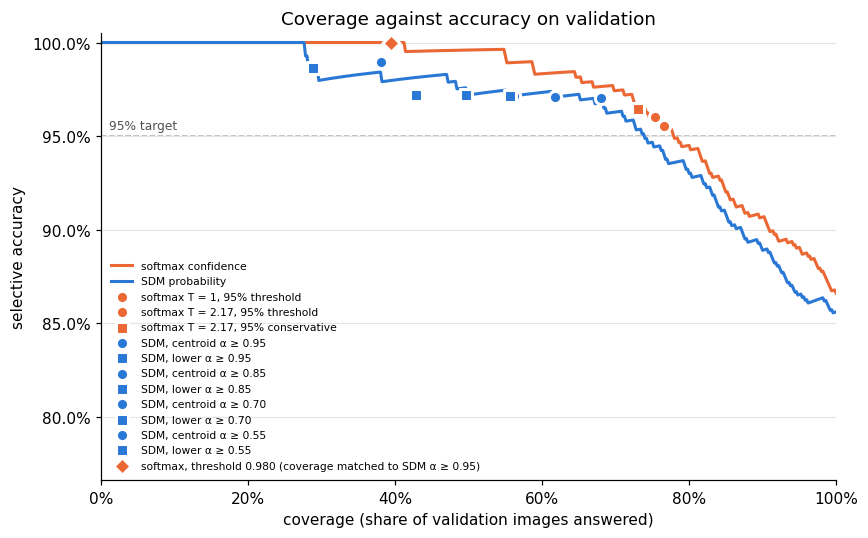

In [9]:
SOFTMAX_COLOR, SDM_COLOR = "#eb6834", "#2a78d6"  # categorical slots 2 and 1 of the reference palette


def coverage_accuracy_curve(score, correct):
    order = np.argsort(-score)
    answered = np.arange(1, len(order) + 1)
    return answered / len(order), np.cumsum(correct[order]) / answered


fig, ax = plt.subplots(figsize=(8, 5))
for label, score, prediction, color in [("softmax confidence", val_conf, val_pred, SOFTMAX_COLOR),
                                        ("SDM probability", scored["probability"], scored["prediction"], SDM_COLOR)]:
    coverage, accuracy = coverage_accuracy_curve(score, prediction == y_val)
    ax.plot(coverage, accuracy, color=color, linewidth=2, label=label)

for rule, (admit, prediction, _) in rules.items():
    if rule == "ResNet, answer everything" or not admit.any():
        continue
    color = SDM_COLOR if rule.startswith("SDM") else SOFTMAX_COLOR
    marker = "s" if "lower" in rule or "conservative" in rule else ("D" if "matched" in rule else "o")
    ax.scatter(admit.mean(), (prediction == y_val)[admit].mean(), s=64, color=color, marker=marker,
               edgecolor="white", linewidth=2, zorder=3, label=rule)

ax.axhline(TARGET_ALPHA, color="#b0afa9", linewidth=1, linestyle="--", zorder=0)
ax.text(0.01, TARGET_ALPHA + 0.004, f"{TARGET_ALPHA:.0%} target", fontsize=8, color="#52514e", transform=ax.get_yaxis_transform())
ax.set(xlabel="coverage (share of validation images answered)", ylabel="selective accuracy",
       xlim=(0, 1), ylim=(max(0.5, (val_pred == y_val).mean() - 0.1), 1.005), title="Coverage against accuracy on validation")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.legend(fontsize=7, frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

### Which classes does each rule answer?

Coverage per true class on validation, for SDM's top region and the conservative softmax threshold, next to the ResNet's accuracy on that class. A rule that tracks reliability should answer the hard classes less.

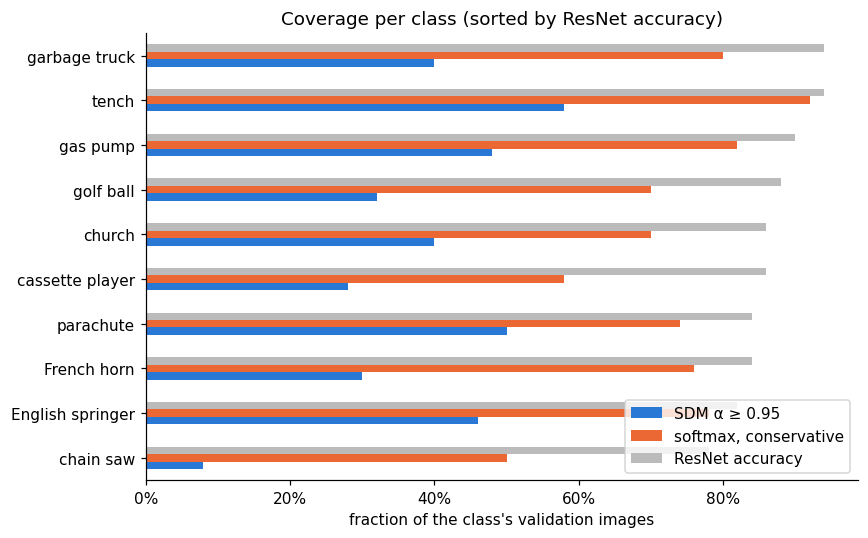

In [10]:
if regions:
    conservative = rules[f"softmax T = {TEMPERATURE:.2f}, 95% conservative"][0]
    per_class = pd.DataFrame({
        f"SDM α ≥ {regions[0]:.2f}": pd.Series(scored["centroid_alpha"] >= regions[0]).groupby(y_val).mean(),
        "softmax, conservative": pd.Series(conservative).groupby(y_val).mean(),
        "ResNet accuracy": pd.Series(val_pred == y_val).groupby(y_val).mean(),
    })
    per_class.index = [class_names[k].replace("_", " ") for k in per_class.index]
    ax = per_class.sort_values("ResNet accuracy").plot.barh(figsize=(8, 5), color=[SDM_COLOR, SOFTMAX_COLOR, "#bbbbbb"])
    ax.set(xlabel="fraction of the class's validation images", title="Coverage per class (sorted by ResNet accuracy)")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    plt.tight_layout()
    plt.show()
else:
    print("SDM formed no region, so it answers nothing.")

## 7. Interpretability by example: the nearest training images

As in notebook 05: each row shows one validation image (left) and its five nearest training images in SDM's embedding space, with their class. The top rows were admitted by SDM's top region; the bottom rows were rejected (α = 0).

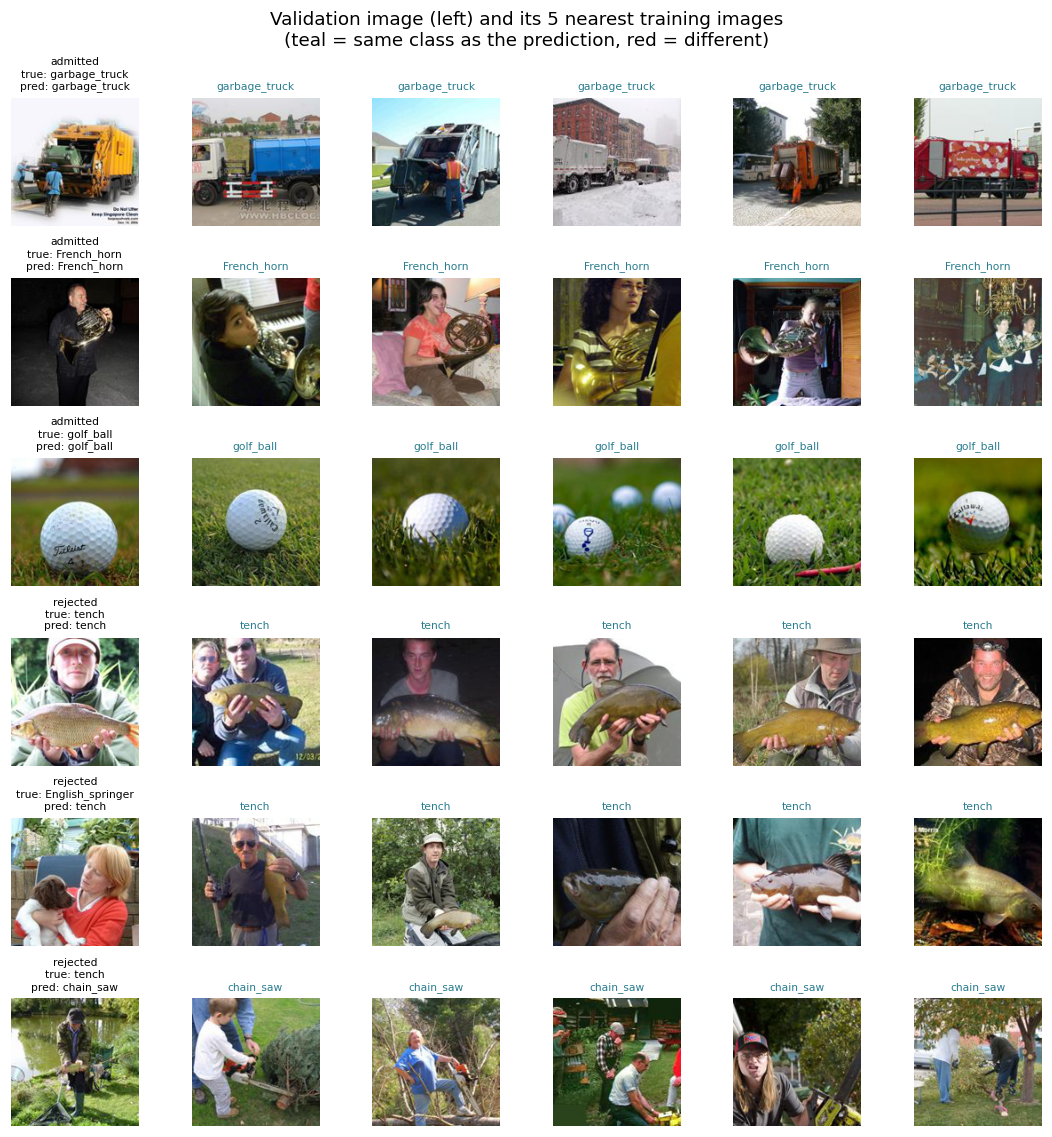

In [11]:
rng = np.random.default_rng(0)
top = regions[0] if regions else np.inf
groups = [("admitted", np.flatnonzero(scored["centroid_alpha"] >= top)), ("rejected", np.flatnonzero(scored["centroid_alpha"] == 0))]
examples = [(i, status) for status, pool in groups for i in rng.choice(pool, size=min(3, len(pool)), replace=False)]
train_index = data["train"]["index"]

fig, axes = plt.subplots(len(examples), 6, figsize=(10, 1.75 * len(examples)), squeeze=False)
for row, (i, status) in enumerate(examples):
    query = data["validation"]["index"][i]
    axes[row, 0].imshow(all_images[query].transpose(1, 2, 0))
    axes[row, 0].set_title(f"{status}\ntrue: {class_names[y_val[i]]}\npred: {class_names[scored['prediction'][i]]}", fontsize=7)
    for ax, match in zip(axes[row, 1:], scored["scores"][i].nearest_support_matches):
        ax.imshow(all_images[train_index[match.support_index]].transpose(1, 2, 0))
        ax.set_title(class_names[match.label], fontsize=7, color="#287c8e" if match.label == scored["prediction"][i] else "#c4553a")
    for ax in axes[row]:
        ax.axis("off")
fig.suptitle("Validation image (left) and its 5 nearest training images\n(teal = same class as the prediction, red = different)", fontsize=12)
plt.tight_layout()
plt.show()

## 8. Imagenette at two resolutions, next to CIFAR-100

The same summary for three ResNet-18s, each computed from its own cached files:

- **Imagenette 128 × 128**: notebooks 08 and 09 as they are.
- **Imagenette 32 × 32**: the same classes, images, splits and training, with `RESOLUTION = 32` in notebook 08 (and `MODEL_NAME = "imagenette32px_resnet18"` here). Against the 128-pixel row, **only the resolution changes**.
- **CIFAR-100**: notebooks 04–05 (100 classes, 100 calibration images per class). Against the 32-pixel Imagenette row, the resolution is the same and **the task changes**.

A row is skipped if its files are missing.

- **train − validation gap**: how much the ResNet memorized its training images. SDM compares new images with these, so a large gap makes its similarity signal less informative.
- **softmax coverage at 95%**: temperature-scaled threshold chosen on calibration for 95% selective accuracy, checked on validation.
- **SDM top region**: the highest α at which SDM formed a region, its validation coverage and accuracy, and the accuracy of a softmax threshold matched to the same coverage.

In [12]:
def summarize(dataset, split_data, temperature, artifact, scored, image_size, calibration_per_class):
    labels = split_data["validation"]["labels"]
    accuracy = {name: (split["logits"].argmax(1).numpy() == split["labels"]).mean() for name, split in split_data.items()}
    cal_conf, cal_pred = softmax_confidence(split_data["calibration"]["logits"], temperature)
    val_conf, val_pred = softmax_confidence(split_data["validation"]["logits"], temperature)
    threshold = choose_threshold(cal_conf, cal_pred == split_data["calibration"]["labels"], TARGET_ALPHA)
    softmax_admit = admitted(val_conf, threshold)
    row = {
        "classes": artifact.manifest["configuration"]["numberOfClasses"],
        "image size": image_size,
        "calibration images per class": calibration_per_class,
        "train accuracy": f"{accuracy['train']:.1%}",
        "validation accuracy": f"{accuracy['validation']:.1%}",
        "train − validation gap": f"{accuracy['train'] - accuracy['validation']:.1%}",
        "softmax coverage at 95%": f"{softmax_admit.mean():.1%} ({(val_pred == labels)[softmax_admit].mean():.1%} accurate)",
        "SDM regions at α": ", ".join(f"{region['alpha']:.2f}" for region in artifact.manifest["regions"]) or "none",
        "SDM top region: coverage (accuracy)": "-",
        "softmax at SDM's coverage: accuracy": "-",
        "AURC softmax / SDM": f"{aurc(val_conf, val_pred == labels):.3f} / {aurc(scored['probability'], scored['prediction'] == labels):.3f}",
    }
    if artifact.manifest["regions"]:
        top_alpha = max(region["alpha"] for region in artifact.manifest["regions"])
        admit = scored["centroid_alpha"] >= top_alpha
        matched = val_conf >= np.quantile(cal_conf, 1 - admit.mean())
        row["SDM top region: coverage (accuracy)"] = f"α ≥ {top_alpha:.2f}: {admit.mean():.1%} ({(scored['prediction'] == labels)[admit].mean():.1%})"
        row["softmax at SDM's coverage: accuracy"] = f"{(val_pred == labels)[matched].mean():.1%}"
    return pd.Series(row, name=dataset)


def load_saved_run(model_name, sdm_name):
    # Another run's checkpoint, cached embeddings and fitted SDM model, rescored on its validation images; None if any file is missing.
    checkpoint_file = OUTPUT_DIR / f"{model_name}.pt"
    embeddings_file = OUTPUT_DIR / f"{model_name}_embeddings.npz"
    sdm_file = OUTPUT_DIR / f"{model_name}_{sdm_name}_epochs{SDM_EPOCHS}_seed{SDM_SEED}.sdmkitmodel"
    if not all(path.exists() for path in [checkpoint_file, embeddings_file, sdm_file]):
        return None
    saved = torch.load(checkpoint_file, map_location="cpu", weights_only=False)
    artifact = load_artifact(sdm_file)
    fingerprint = f"{model_name}_avgpool512_{hashlib.sha256(checkpoint_file.read_bytes()).hexdigest()[:16]}"
    assert artifact.manifest["representation"]["fingerprint"] == fingerprint, f"{sdm_file.name} is stale: rerun the notebook that fits it"
    with np.load(embeddings_file) as cache:
        split_data = {name: {"embeddings": cache[f"{name}_embeddings"], "logits": torch.from_numpy(cache[f"{name}_logits"]),
                             "labels": cache[f"{name}_labels"]} for name in ["train", "validation", "calibration"]}
    return saved, split_data, artifact, score_validation(SDMModel(artifact, device=str(device)), split_data["validation"]["embeddings"])


RUNS = [  # (row name, model name, SDM model name, how to produce it)
    ("Imagenette 128 × 128", "imagenette_resnet18", "sdm10", "notebooks 08 and 09"),
    ("Imagenette 32 × 32", "imagenette32px_resnet18", "sdm10", "notebooks 08 and 09 with RESOLUTION = 32"),
    ("CIFAR-100", CIFAR_MODEL_NAME, "sdm_fine100", "notebooks 04 and 05"),
]
summaries = []
for dataset, model_name, sdm_name, source in RUNS:
    if model_name == MODEL_NAME:
        summaries.append(summarize(dataset, data, TEMPERATURE, sdm, scored, f"{settings['crop_size']} × {settings['crop_size']}", settings["cal_per_class"]))
        continue
    run = load_saved_run(model_name, sdm_name)
    if run is None:
        print(f"{dataset}: files not found; run {source} to add it.")
        continue
    saved, split_data, artifact, run_scored = run
    size = saved["settings"].get("crop_size", 32)
    summaries.append(summarize(dataset, split_data, saved["temperature"], artifact, run_scored, f"{size} × {size}", saved["settings"]["cal_per_class"]))

pd.concat(summaries, axis=1)

,Imagenette 128 × 128,Imagenette 32 × 32,CIFAR-100
classes,10,10,100
image size,128 × 128,32 × 32,32 × 32
calibration images per class,200,200,100
train accuracy,100.0%,100.0%,99.3%
validation accuracy,86.6%,84.2%,72.0%
train − validation gap,13.4%,15.8%,27.3%
softmax coverage at 95%,75.4% (96.0% accurate),70.4% (95.5% accurate),49.5% (94.5% accurate)
SDM regions at α,"0.95, 0.85, 0.70, 0.55","0.95, 0.80, 0.65",none
SDM top region: coverage (accuracy),α ≥ 0.95: 38.0% (98.9%),α ≥ 0.95: 39.4% (100.0%),-
softmax at SDM's coverage: accuracy,100.0%,100.0%,-


## 9. What we learned

Numbers below are from our run (one ResNet seed, 500 validation images); rerunning with a different checkpoint will change them.

1. **SDM now forms regions on every class.** On Imagenette it formed regions at α = 0.95, 0.85, 0.70 and 0.55, on all 10 classes; on CIFAR-100 it formed none. At α ≥ 0.95 it answers **38% of validation images at 98.9% accuracy** (95% interval 96.2–99.7%), so its promise holds on images it was not calibrated on.
2. **A softmax threshold still does at least as well at the same coverage.** Raised to match SDM's coverage (threshold 0.98), the temperature-scaled softmax answers 39.4% of images at 100% accuracy, with every class at 100% precision. The difference is 2 errors out of 190 against 0 out of 197, and the intervals overlap, so on 500 images the two are statistically indistinguishable. SDM is not *better* here.
3. **At the 95% target, softmax answers more.** The temperature-scaled 95% threshold answers 75% of images at 96.0%; SDM's lowest region (α ≥ 0.55) answers 68% at 97.1%. SDM's α is a stricter, per-class promise, and that costs coverage.
4. **As a ranking score, softmax is still better:** AURC 0.026 against 0.037 for SDM's probability, AUROC 0.886 against 0.846. The same ordering as CIFAR-100.
5. **Memorization did not go away.** The ResNet is right on 100% of its training images (CIFAR-100: 99.3%), so SDM's similarity signal (do the nearest training images agree?) still adds little to what the softmax already knows. The train − validation gap is smaller (13% against 27%) only because validation accuracy is higher.

6. **Resolution is not what made the difference.** The same Imagenette task at 32 × 32 (section 8) behaves almost exactly like the 128-pixel run: 84.2% validation accuracy against 86.6%, SDM regions on all 10 classes up to α = 0.95 (39% of images answered, all correct), and the same pattern against softmax (coverage-matched softmax also 100% correct; AURC 0.030 against 0.037). The change from CIFAR-100 to Imagenette comes from the **task**: 10 distinct classes with 200 calibration images each, instead of 100 classes, several of them confusable, with 100 each.

**Takeaway:** the easier task fixes SDM's *feasibility* problem: it forms high-α regions on every class, and they hold on validation. It does not give SDM an *accuracy* advantage over a well-chosen softmax threshold, at either resolution.

**Next experiments:**

- **Harder classes at high resolution:** Imagewoof (10 dog breeds, same format). It tests whether confusable classes block SDM again, now with plenty of pixels.
- **Where SDM should differ:** images from outside the training classes (out-of-distribution), for example Imagewoof or CIFAR images shown to this model. There SDM's distance signal can reject them, and the softmax cannot.
- **Less memorization:** stronger augmentation or early stopping, then check whether SDM's ranking catches up.
- **Separate the class count from the calibration size:** on CIFAR-100, SDM on the 20 broader groups (notebook 05) already formed regions; a 10-class CIFAR subset would complete the picture.
